##NAME: ريتاج خالد الاشقر
##ID: 446008786

## Introduction

In this lab session, we will work with the IMDB dataset, a binary sentiment classification task (predicting whether a movie review is positive or negative).

__The main objective__ of today's lab is to learn how to tune different hyperparameters — including the number of hidden layers, number of neurons per layer, learning rate, and optimizer — using __K-fold Cross Validation__ to get a more robust performance estimate than a single train/validation split would give. We will also explore how model *capacity* and *regularization* (Dropout) affect overfitting.

#Loading the data and Preprocess it

In [1]:
#Import numpy, pandas and tensorflow packages that we will use here.
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import cross_val_score, KFold
from tensorflow import keras
from tensorflow.keras import backend as K


from tensorflow.keras.datasets import imdb
(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=10000)

# set seed for replicability of results
np.random.seed(1)
tf.random.set_seed(2)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [2]:
# Make sure you load the data with its correct shape (25000,)
train_data.shape


(25000,)

In [3]:
train_labels.shape

(25000,)

In [4]:
# To shuffle the entire DataFrame (both text and label together), we need to combine data and lebels
train_df = pd.DataFrame(train_data)
label_df = pd.DataFrame(train_labels, columns=["label"])

# Combine along columns (axis=1)
training_set = pd.concat([train_df, label_df], axis=1)
training_set.rename(columns={0: "text"}, inplace=True)

print(training_set.shape)  # (rows, columns+1)

(25000, 2)


In [5]:
test_df = pd.DataFrame(test_data)
label_df = pd.DataFrame(test_labels, columns=["label"])

# Combine along columns (axis=1)
test_set = pd.concat([test_df, label_df], axis=1)
test_set.rename(columns={0: "text"}, inplace=True)

print(test_set.shape)  # (rows, columns+1)

(25000, 2)


In [6]:
#Preprocess the data
from sklearn.utils import shuffle
from tensorflow.keras.preprocessing import text, sequence
from tensorflow.keras import utils

# Shuffle dataset
training_set = shuffle(training_set)

test_set = shuffle(test_set)

# Obtain text and label vectors
train_texts = training_set.text
train_labels = training_set.label


test_texts = test_set.text
test_labels = test_set.label

In [7]:
#Encoding the integer sequences via multi-hot encoding
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension))

    for i, sequence in enumerate(sequences):
      for j in sequence:
          results[i, j] = 1.
    return results
x_train = vectorize_sequences(train_texts)
x_test = vectorize_sequences(test_texts)

In [8]:
# You Should also vectorize the labels
y_train = np.asarray(train_labels).astype("float32")
y_test = np.asarray(test_labels).astype("float32")

# Hyperparameters Tuning

Now, we are trying to improve the model's performance by tuning your hyperparameters using K-fold cross validation.
Build new models with different values for the learning rate (e.g., 0.001, 0.1), try different optimizers (SGD, RMSprop), experiment with the number of epochs, or even build a deeper model! Enjoy exploring! ;)



1.   Define Hyperparameters to Test (hidden layer, number of neurons, learning rate, optimizers) and specify their different values to test.
2.   For EACH Hyperparameter Combination
      - Run 3-Fold Cross-Validation:
          - Train on 2/3 of training data
          - Validate on 1/3 of training data
          - Repeat 3 times (different folds)
      - Calculate mean **and standard deviation** of accuracy across folds
      - Store results
3. Select Best Hyperparameters with highest mean CV accuracy
4. Pick this hyperparameter combination
5. Train Final Model with all your training data (25000 examples)
6. Evaluate on Test Set and report the accuracy
7. Add Dropout regularization to your best model and compare overfitting/accuracy before vs. after

**Note on epochs:** to keep the total search time manageable, epochs are fixed at 10 for every combination during the CV search below. You will revisit this for your final model later, based on where overfitting begins in your best combination's loss curves.

## Step 1: Specify a different value for each parameters



**Note:** `n_hidden` and `n_neurons` control your model's *capacity* — its ability to represent complex patterns in the data. Higher capacity can fit the training data better, but also raises the risk of overfitting. `learning_rate` and `optimizer_name` instead control *how* the model learns (the optimization process itself). Keep this distinction in mind as you look at the results below — you'll see it show up directly in the training curves.

In [9]:
param_distribs = {
    "n_hidden": [1, 2],
    "n_neurons": [32, 64],
    "learning_rate": [0.001, 0.01],
    "optimizer_name": ["SGD", "RMSprop"]
}

**Here we generate all possible combinations**


In [10]:
import itertools
param_combinations = [
    {"n_hidden": h, "n_neurons": n, "learning_rate": lr, "optimizer_name": opt}
    for h, n, lr, opt in itertools.product(
        param_distribs["n_hidden"],
        param_distribs["n_neurons"],
        param_distribs["learning_rate"],
        param_distribs["optimizer_name"]
    )
]

# Check all combinations
for comboination in param_combinations:
    print(comboination) # you will get 16 combinations (2*2*2*2)

{'n_hidden': 1, 'n_neurons': 32, 'learning_rate': 0.001, 'optimizer_name': 'SGD'}
{'n_hidden': 1, 'n_neurons': 32, 'learning_rate': 0.001, 'optimizer_name': 'RMSprop'}
{'n_hidden': 1, 'n_neurons': 32, 'learning_rate': 0.01, 'optimizer_name': 'SGD'}
{'n_hidden': 1, 'n_neurons': 32, 'learning_rate': 0.01, 'optimizer_name': 'RMSprop'}
{'n_hidden': 1, 'n_neurons': 64, 'learning_rate': 0.001, 'optimizer_name': 'SGD'}
{'n_hidden': 1, 'n_neurons': 64, 'learning_rate': 0.001, 'optimizer_name': 'RMSprop'}
{'n_hidden': 1, 'n_neurons': 64, 'learning_rate': 0.01, 'optimizer_name': 'SGD'}
{'n_hidden': 1, 'n_neurons': 64, 'learning_rate': 0.01, 'optimizer_name': 'RMSprop'}
{'n_hidden': 2, 'n_neurons': 32, 'learning_rate': 0.001, 'optimizer_name': 'SGD'}
{'n_hidden': 2, 'n_neurons': 32, 'learning_rate': 0.001, 'optimizer_name': 'RMSprop'}
{'n_hidden': 2, 'n_neurons': 32, 'learning_rate': 0.01, 'optimizer_name': 'SGD'}
{'n_hidden': 2, 'n_neurons': 32, 'learning_rate': 0.01, 'optimizer_name': 'RMSprop'

__Building the model Function__

In [11]:
def build_model(n_hidden, n_neurons, learning_rate, optimizer_name, shape, dropout_rate=0.0):
    model = keras.models.Sequential()

    for layer in range(n_hidden):
        model.add(keras.layers.Dense(n_neurons, activation="relu"))
        if dropout_rate > 0:
            model.add(keras.layers.Dropout(dropout_rate))

    model.add(keras.layers.Dense(1, activation='sigmoid'))

    # Choose optimizer dynamically
    if optimizer_name == "SGD":
        optimizer = keras.optimizers.SGD(learning_rate=learning_rate)
    elif optimizer_name == "RMSprop":
         optimizer = keras.optimizers.RMSprop(learning_rate=learning_rate)


    model.compile(loss="binary_crossentropy", optimizer=optimizer, metrics=["accuracy"])
    return model

# Note: dropout_rate defaults to 0.0 (no dropout), so this function still works exactly
# as before for Steps 1-4. We'll pass a non-zero dropout_rate in Step 5 to add regularization.

##Step 2: Implement K-Fold CV to compare our all possible hyperparameter combinations.

Note: during the training, we use the same validation fold to monitor overfitting.

In [12]:
from tensorflow import keras
from tensorflow.keras import backend as K
kf = KFold(n_splits=3, shuffle=True, random_state=42)
results = []

# Loop over hyperparameter combinations
for combo_idx, params in enumerate(param_combinations):
    print(f"\n{'='*60}")
    print(f"Testing combination {combo_idx+1}/{len(param_combinations)}")
    print(f"Params: {params}")
    print(f"{'='*60}")
    fold_acc = []
    fold_loss = []

    for fold_num, (train_idx, val_idx) in enumerate(kf.split(x_train), 1):
        X_tr, X_val = x_train[train_idx], x_train[val_idx]
        y_tr, y_val = y_train[train_idx], y_train[val_idx]

        # Build model for this fold using specific combination
        model = build_model(
            n_hidden=params["n_hidden"],
            n_neurons=params["n_neurons"],
            learning_rate=params["learning_rate"],
            optimizer_name=params["optimizer_name"],
            shape=X_tr.shape[1]
        )

        # Train model
        print(f"Training with params: {params}")
        model.fit(X_tr, y_tr, epochs=10, batch_size=512, validation_data=(X_val, y_val), verbose=1)

        # Evaluate fold
        print("\n" + "="*60)
        print(f"Testing Fold {fold_num}/3 with params: {params}")
        loss,acc = model.evaluate(X_val, y_val, verbose=1)
        print("\n" + "="*60)
        fold_acc.append(acc)
        fold_loss.append(loss)

        # Clear memory to prevent crashes
        #K.clear_session()

    mean_acc = np.mean(fold_acc)
    std_acc = np.std(fold_acc)
    mean_loss = np.mean(fold_loss)

    results.append({
        "params": params,
        "cv_accuracy": mean_acc,
        "cv_std": std_acc,
        "cv_loss": mean_loss
    })


Testing combination 1/16
Params: {'n_hidden': 1, 'n_neurons': 32, 'learning_rate': 0.001, 'optimizer_name': 'SGD'}
Training with params: {'n_hidden': 1, 'n_neurons': 32, 'learning_rate': 0.001, 'optimizer_name': 'SGD'}
Epoch 1/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.5096 - loss: 0.6940 - val_accuracy: 0.5118 - val_loss: 0.6941
Epoch 2/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.5169 - loss: 0.6928 - val_accuracy: 0.5206 - val_loss: 0.6930
Epoch 3/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.5235 - loss: 0.6918 - val_accuracy: 0.5247 - val_loss: 0.6919
Epoch 4/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.5319 - loss: 0.6908 - val_accuracy: 0.5330 - val_loss: 0.6909
Epoch 5/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.5404 - loss: 0.6898 - val_accuracy: 0.5433 - val_loss: 0.6900
Epoch 6/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.5489 - loss: 0.6888 - val_accuracy: 0.5492 - val_loss: 0.6890
Epoch 7/10
33/33 ━

##Step 3: Select Best Hyperparameters with highest mean CV accuracy


In [13]:
# Sort results by accuracy descending (best first)
results_sorted = sorted(results, key=lambda x: x["cv_accuracy"], reverse=True)

# Print (now including the standard deviation across folds — a combination with a
# high mean but also high std is less trustworthy than one that's consistently good)
for r in results_sorted:
    print(f"Params: {r['params']}, CV Accuracy: {r['cv_accuracy']:.4f} ± {r['cv_std']:.4f}, CV Loss: {r['cv_loss']:.4f}")

Params: {'n_hidden': 1, 'n_neurons': 32, 'learning_rate': 0.001, 'optimizer_name': 'RMSprop'}, CV Accuracy: 0.8825 ± 0.0046, CV Loss: 0.3107
Params: {'n_hidden': 1, 'n_neurons': 64, 'learning_rate': 0.001, 'optimizer_name': 'RMSprop'}, CV Accuracy: 0.8819 ± 0.0036, CV Loss: 0.3202
Params: {'n_hidden': 1, 'n_neurons': 64, 'learning_rate': 0.01, 'optimizer_name': 'RMSprop'}, CV Accuracy: 0.8801 ± 0.0022, CV Loss: 0.4064
Params: {'n_hidden': 2, 'n_neurons': 64, 'learning_rate': 0.01, 'optimizer_name': 'RMSprop'}, CV Accuracy: 0.8799 ± 0.0013, CV Loss: 0.5524
Params: {'n_hidden': 2, 'n_neurons': 64, 'learning_rate': 0.001, 'optimizer_name': 'RMSprop'}, CV Accuracy: 0.8796 ± 0.0021, CV Loss: 0.3915
Params: {'n_hidden': 2, 'n_neurons': 32, 'learning_rate': 0.01, 'optimizer_name': 'RMSprop'}, CV Accuracy: 0.8796 ± 0.0025, CV Loss: 0.5916
Params: {'n_hidden': 1, 'n_neurons': 32, 'learning_rate': 0.01, 'optimizer_name': 'RMSprop'}, CV Accuracy: 0.8783 ± 0.0005, CV Loss: 0.4223
Params: {'n_hidde

###**Question 1: What is the best Hyperparameters combination ?**

The best hyperparameter combination was 1 hidden layer with 32 neurons, a learning rate of 0.001, and the RMSprop optimizer. It achieved the highest mean cross-validation accuracy of 88.25% (± 0.46%), with a CV loss of 0.3107

###**Question 2: Look at the results table above. Compare the CV accuracy of **SGD with learning_rate=0.001** to **RMSprop with the same learning_rate**. Using what you learned about gradient descent and learning rate, explain the difference you see.**

RMSprop performed much better than SGD with the same learning rate of 0.001. For example, with 1 hidden layer and 32 neurons, RMSprop achieved 88.25% CV accuracy, while SGD achieved 56.88%. RMSprop adapts the learning rate based on recent gradients, which helps it learn faster. SGD uses a fixed learning rate, so 0.001 was too small for it to learn effectively within 10 epochs.

**Note: after you pick the best hyperparameters, go back to the training results and make sure there is no overfitting during the training. If there is, try reducing the number of epochs in the next step and check if it is still overfitting.**

##Step 4 : Evaluate on the test set
First, you need to train a model using your best hyperparameters, train it on the full training data, and then test it on the test set.

**Note: do not forget to check if there is overfitting during the training.**

Best hyperparameters: {'n_hidden': 1, 'n_neurons': 32, 'learning_rate': 0.001, 'optimizer_name': 'RMSprop'}
Epoch 1/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.8069 - loss: 0.4634 - val_accuracy: 0.7908 - val_loss: 0.4452
Epoch 2/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.9008 - loss: 0.2917 - val_accuracy: 0.8768 - val_loss: 0.3170
Epoch 3/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.9168 - loss: 0.2353 - val_accuracy: 0.8908 - val_loss: 0.2791
Epoch 4/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.9300 - loss: 0.2011 - val_accuracy: 0.8864 - val_loss: 0.2853
Epoch 5/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.9380 - loss: 0.1797 - val_accuracy: 0.8912 - val_loss: 0.2728
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8827 - loss: 0.2888

Test Accuracy: 0.8827
Test Loss: 0.2888


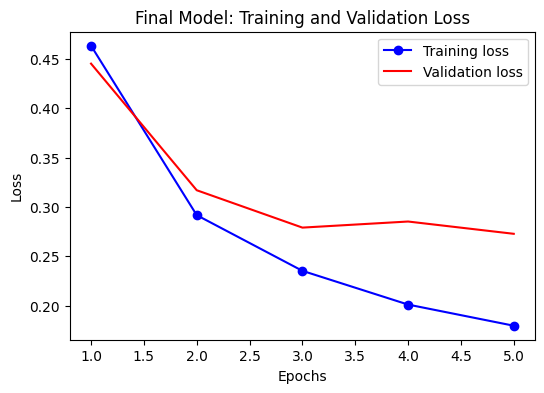

In [18]:
import matplotlib.pyplot as plt

# Get the best hyperparameters found during Step 3
best_params = results_sorted[0]["params"]
print("Best hyperparameters:", best_params)

# Note: choose the number of epochs based on where your Step 2 CV training curves
# started to overfit (see the per-epoch logs printed for your best combination above).
# epochs=10 is used here as a starting point -- reduce it if val_loss was already
# increasing before epoch 10 for this combination.
best_epochs = 5

final_model = build_model(
    n_hidden=best_params["n_hidden"],
    n_neurons=best_params["n_neurons"],
    learning_rate=best_params["learning_rate"],
    optimizer_name=best_params["optimizer_name"],
    shape=x_train.shape[1]
)

# A small validation_split is kept here purely so we can visualize the loss curve
# and confirm there's no overfitting at the chosen epoch count -- the model is
# still trained using (and benefits from) the full training set.
history_final = final_model.fit(
    x_train, y_train,
    epochs=best_epochs,
    batch_size=512,
    validation_split=0.2,
    verbose=1
)

test_loss, test_acc = final_model.evaluate(x_test, y_test, verbose=1)
print(f"\nTest Accuracy: {test_acc:.4f}")
print(f"Test Loss: {test_loss:.4f}")

# Quick overfitting check for this final run
h = history_final.history
epochs_range = range(1, len(h["loss"]) + 1)
plt.figure(figsize=(6, 4))
plt.plot(epochs_range, h["loss"], "bo-", label="Training loss")
plt.plot(epochs_range, h["val_loss"], "r-", label="Validation loss")
plt.title("Final Model: Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

##After observation
the model showed overfitting when trained for 10 epochs because the training loss continued to decrease while the validation loss started to increase. I reduced the training to 5 epochs, which reduced the overfitting. The final model achieved a test accuracy of 88.27% and a test loss of 0.2888, which was better than the result with 10 epochs.

****

#Regularization: Comparing With vs. Without Dropout

Look back at your training curves from Step 2 — for most hyperparameter combinations, training accuracy climbs toward ~0.95-0.98 while validation loss starts *increasing* after a few epochs. That's overfitting: the model is memorizing the training data rather than generalizing to new examples.

**Dropout** is a regularization technique that randomly "drops" (zeroes out) a fraction of neurons during training. This prevents the network from relying too heavily on any single neuron, which tends to reduce overfitting.

`build_model` above already supports a `dropout_rate` parameter (default `0.0` = no dropout). Now, reuse your **best hyperparameter combination from Step 3** and compare a few dropout rates using the same 3-fold CV approach from Step 2.

**Important:** Dropout should only be active during *training*. Keras handles this automatically — it is turned off during `model.evaluate()` and `model.predict()` — so you don't need to do anything extra for that.

In [16]:
best_params = results_sorted[0]["params"]
print("Best hyperparameters from Step 3:", best_params)

dropout_results = []

for dropout_rate in [0.0, 0.3, 0.5]:
    print(f"\n{'='*60}")
    print(f"Testing dropout_rate = {dropout_rate}")
    print(f"{'='*60}")
    fold_acc = []
    fold_loss = []

    for fold_num, (train_idx, val_idx) in enumerate(kf.split(x_train), 1):
        X_tr, X_val = x_train[train_idx], x_train[val_idx]
        y_tr, y_val = y_train[train_idx], y_train[val_idx]

        model = build_model(
            n_hidden=best_params["n_hidden"],
            n_neurons=best_params["n_neurons"],
            learning_rate=best_params["learning_rate"],
            optimizer_name=best_params["optimizer_name"],
            shape=X_tr.shape[1],
            dropout_rate=dropout_rate
        )

        print(f"Training fold {fold_num}/3 with dropout_rate={dropout_rate}")
        model.fit(X_tr, y_tr, epochs=10, batch_size=512, validation_data=(X_val, y_val), verbose=1)

        loss, acc = model.evaluate(X_val, y_val, verbose=1)
        fold_acc.append(acc)
        fold_loss.append(loss)

    dropout_results.append({
        "dropout_rate": dropout_rate,
        "cv_accuracy": np.mean(fold_acc),
        "cv_std": np.std(fold_acc),
        "cv_loss": np.mean(fold_loss)
    })

print("\n" + "="*60)
print("Dropout comparison results (using best hyperparameters from Step 3):")
for r in dropout_results:
    print(f"Dropout: {r['dropout_rate']}, CV Accuracy: {r['cv_accuracy']:.4f} ± {r['cv_std']:.4f}, CV Loss: {r['cv_loss']:.4f}")

Best hyperparameters from Step 3: {'n_hidden': 1, 'n_neurons': 32, 'learning_rate': 0.001, 'optimizer_name': 'RMSprop'}

Testing dropout_rate = 0.0
Training fold 1/3 with dropout_rate=0.0
Epoch 1/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 77ms/step - accuracy: 0.7946 - loss: 0.4831 - val_accuracy: 0.8728 - val_loss: 0.3665
Epoch 2/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.8976 - loss: 0.3011 - val_accuracy: 0.8900 - val_loss: 0.2996
Epoch 3/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.9206 - loss: 0.2369 - val_accuracy: 0.8954 - val_loss: 0.2784
Epoch 4/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.9320 - loss: 0.2017 - val_accuracy: 0.8958 - val_loss: 0.2738
Epoch 5/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9399 - loss: 0.1769 - val_accuracy: 0.8906 - val_loss: 0.2759
Epoch 6/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.9474 - loss: 0.1594 - val_accuracy: 0.8944 - val_loss: 0.2759
Epoch 7/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step


##Question 4: Plot the training and validation loss curves for your best combination with `dropout_rate=0.0` vs. `dropout_rate=0.5` (side by side, similar to what you did in Lab 4).

- Did the gap between training and validation loss shrink with dropout?
- Did CV accuracy improve, stay about the same, or get worse?
- Dropout doesn't always help — based on what you observed, explain why it might not.

##Answer:
Yes, the gap between the training and validation loss became smaller with dropout = 0.5, which means dropout helped reduce overfitting.  
The CV accuracy also improved slightly, from 88.23% with no dropout to 88.75% with dropout = 0.5. The CV loss also decreased from 0.3149 to 0.2955.  
Dropout does not always help because removing too many neurons during training can make the model learn less effectively and may cause underfitting. However, in this case, dropout helped the model generalize better and slightly improved its performance.

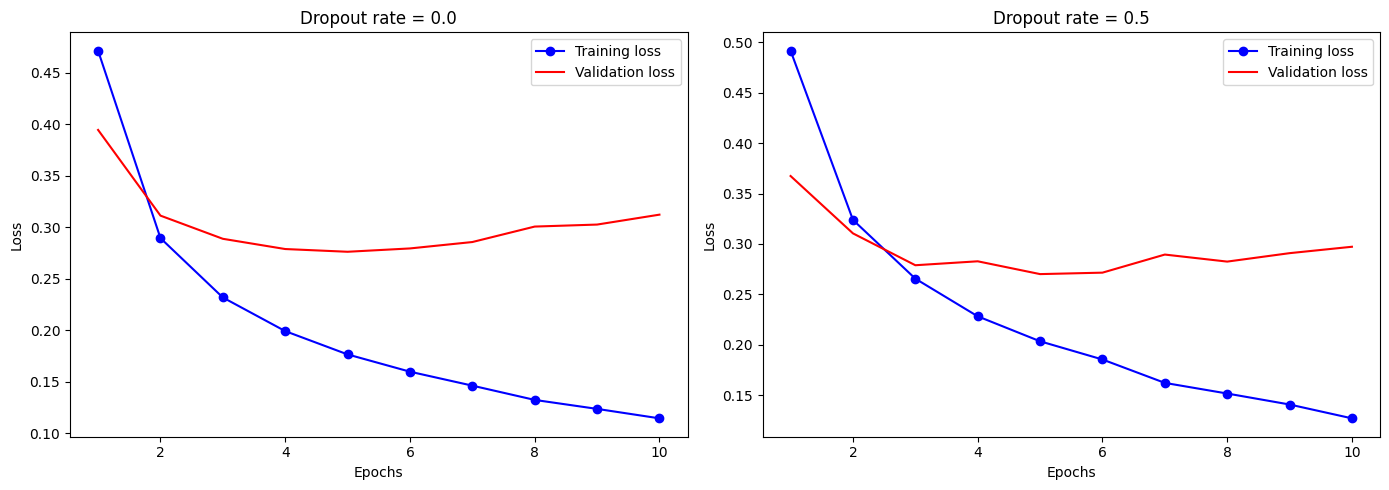

In [19]:
import matplotlib.pyplot as plt

best_params = results_sorted[0]["params"]

# Hold out a validation slice purely to visualize the effect of dropout on the
# loss curves (separate from the CV folds used above, just for this comparison plot)
x_val_plot = x_train[:5000]
y_val_plot = y_train[:5000]
x_train_plot = x_train[5000:]
y_train_plot = y_train[5000:]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, dropout_rate in zip(axes, [0.0, 0.5]):
    model = build_model(
        n_hidden=best_params["n_hidden"],
        n_neurons=best_params["n_neurons"],
        learning_rate=best_params["learning_rate"],
        optimizer_name=best_params["optimizer_name"],
        shape=x_train_plot.shape[1],
        dropout_rate=dropout_rate
    )

    history = model.fit(
        x_train_plot, y_train_plot,
        epochs=10,
        batch_size=512,
        validation_data=(x_val_plot, y_val_plot),
        verbose=0
    )

    h = history.history
    epochs_range = range(1, len(h["loss"]) + 1)
    ax.plot(epochs_range, h["loss"], "bo-", label="Training loss")
    ax.plot(epochs_range, h["val_loss"], "r-", label="Validation loss")
    ax.set_title(f"Dropout rate = {dropout_rate}")
    ax.set_xlabel("Epochs")
    ax.set_ylabel("Loss")
    ax.legend()

plt.tight_layout()
plt.show()